<a href="https://colab.research.google.com/github/jimenezjos/Aplicaciones/blob/main/MCMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Implementación del Algoritmo de Metropolis
### **Caminata Aleatoria para una Distribución Bivariada**

**1. Formulación del Problema**
En este ejercicio implementaremos el algoritmo de Metropolis para generar muestras de una distribución de probabilidad bivariada. La función de densidad (no normalizada) que queremos simular está dada por la siguiente expresión:

$$ f(x) = c*\exp\left( -0.5 \left( x_1^2 x_2^2 + x_1^2 + x_2^2 - 8x_1 - 8x_2 \right) \right) $$

**2. Descripción del Método**
Para resolver esto, utilizamos métodos de **MCMC (Cadenas de Markov de Monte Carlo)**, específicamente una caminata aleatoria de Metropolis. El método funciona así:
* Partimos de un punto inicial $X_0$.
* Proponemos un nuevo punto $Y$ sumando un "salto" aleatorio basado en una distribución normal.
* Calculamos una probabilidad de aceptación comparando el valor de la función en el punto propuesto vs. el actual.
* Decidimos si nos movemos al nuevo punto o nos quedamos en el actual. Repetimos el proceso $N$ veces.

In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
def f(x):
    x1, x2 = x[0], x[1]
    # f(x) = C * exp(-0.5 * (x1^2 * x2^2 + x1^2 + x2^2 - 8*x1 - 8*x2))
    exponente = -0.5 * (x1**2 * x2**2 + x1**2 + x2**2 - 8*x1 - 8*x2)
    return np.exp(exponente)

In [3]:
def caminata_aleatoria_metropolis(n_iteraciones, x_inicial):

    X_t = np.array(x_inicial, dtype=float)

    muestras = np.zeros((n_iteraciones, 2))
    muestras[0] = X_t

    for t in range(1, n_iteraciones):

        Z = np.random.normal(0,1, size=2)
        Y=X_t + Z

        f_Y = f(Y)
        f_X = f(X_t)

        if f_X > 0:
            alpha = min(1.0, f_Y / f_X)
        else:
            alpha = 0.0

        U = np.random.uniform(0.0, 1.0)

        if U <= alpha:
            X_t = Y

        muestras[t] = X_t

    return muestras


## 3. Solución Final y Visualización de Resultados

Graficamos los resultados finales para entender visualmente la distribución.
Se presentan dos visualizaciones para un análisis completo:
1. **Gráfico de dispersión 2D**: Muestra la concentración de las muestras en el plano $(x_1, x_2)$.
2. **Histograma 3D**: Representa frecuencias mediante mapas de calor.

Simulando 10000 iteraciones...


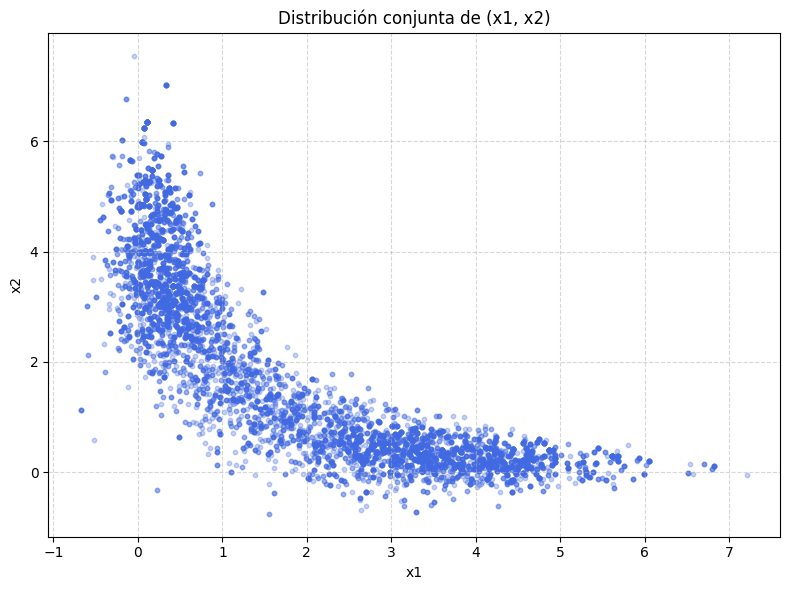

In [9]:
N = 10000
x_0 = [0, 0]

print(f"Simulando {N} iteraciones...")
resultados = caminata_aleatoria_metropolis(N, x_0)

resultados_validos = resultados[1000:]
x1_muestras = resultados_validos[:, 0]
x2_muestras = resultados_validos[:, 1]

plt.figure(figsize=(8, 6))

# Gráfica de dispersión de puntos
plt.scatter(x1_muestras, x2_muestras, alpha=0.3, s=10, color='royalblue')

plt.title("Distribución conjunta de (x1, x2)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [10]:
print(np.median(resultados[:, 0]))

1.6565874994944731


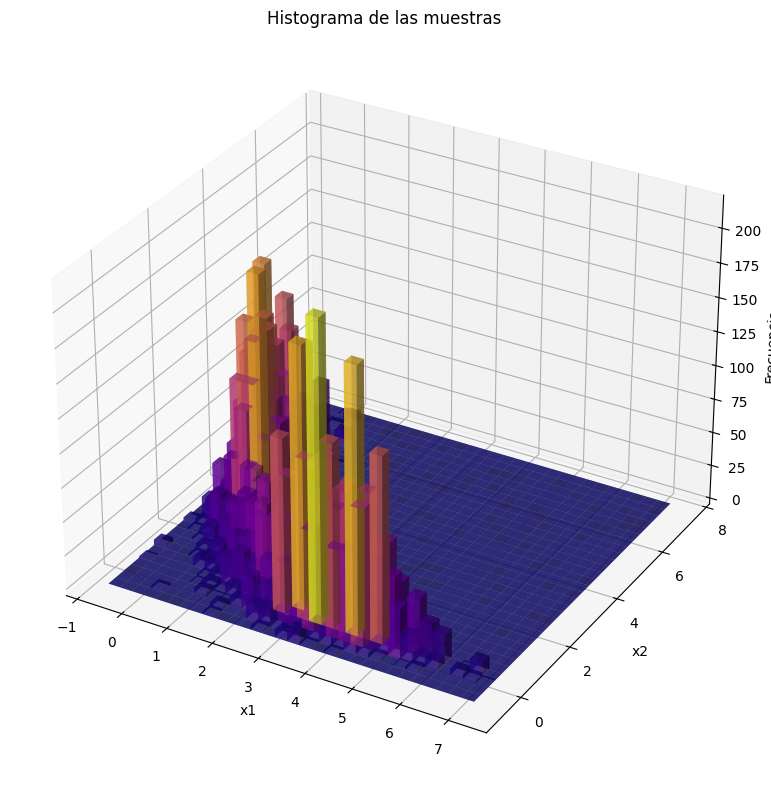

In [17]:
bins = 30
hist, xedges, yedges = np.histogram2d(x1_muestras, x2_muestras, bins=bins)

xpos, ypos = np.meshgrid(xedges[:-1], yedges[:-1], indexing="ij")
xpos = xpos.ravel()
ypos = ypos.ravel()
zpos = np.zeros_like(xpos)

dx = xedges[1] - xedges[0]
dy = yedges[1] - yedges[0]
dz = hist.ravel()

cmap = plt.cm.plasma
norm = plt.Normalize(dz.min(), dz.max())
colors = cmap(norm(dz))

fig = plt.figure(figsize=(16, 8))
ax = fig.add_subplot(111, projection='3d')

ax.bar3d(xpos, ypos, zpos, dx, dy, dz, color=colors, alpha=0.6, zsort='average')

ax.set_title('Histograma de las muestras')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('Frecuencia')
plt.tight_layout()
plt.show()